# Day 36: Temporal validation framework design

**Phase 3: Predictive Modeling**

## Objective
Temporal validation framework design

## Task
Implement src/validation/temporal_cv.py module with SeasonBasedSplit, ExpandingWindowSplit, RollingWindowSplit. Never use random split. Document why with data leakage examples.

**Deliverable:** Temporal validation module + notebook comparing random vs temporal split.

---

### Instructions:
*Treat this as your course workbook. Write your code, notes, or execution steps below.*

Remember: 
- Document your decisions.
- Use clear variable names.
- If today's task involves creating a script in `src/`, a dashboard in `apps/`, or documentation in `docs/`, you can use this notebook to test your logic or simply write your reflections and proofs of execution (e.g. running terminal commands with `!`).



## 1. Temporal Validation Architecture & `BaseCrossValidator` Contract

**Objective:** Design a scikit-learn compatible temporal cross-validation module (`src/validation/temporal_cv.py`) implementing `SeasonBasedSplit`, `ExpandingWindowSplit`, and `RollingWindowSplit`, and audit our Phase 2 temporal datasets to verify chronological ordering.

**Methodological Rationale:** Sports event and play-by-play datasets violate the i.i.d. assumption. Standard random `KFold` leaks future outcomes and overlapping rolling-window statistics into training folds, artificially inflating validation metrics. Inheriting from `sklearn.model_selection.BaseCrossValidator` guarantees drop-in compatibility with `cross_val_score`, `cross_validate`, and `GridSearchCV`.

**Hypothesis:** Enforcing strict past-to-future splits will eliminate look-ahead leakage and expose realistic generalization error compared to random `KFold`.

In [6]:
from pathlib import Path
import pandas as pd

cwd = Path.cwd()
REPO_ROOT = cwd if (cwd / "data").exists() else cwd.parent.parent

draft_df = pd.read_parquet(REPO_ROOT / "data" / "features" / "nfl" / "draft_features.parquet")
nfl_temp_df = pd.read_parquet(REPO_ROOT / "data" / "processed" / "nfl" / "features_team_temporal_2023.parquet")

print(f"Draft feature store: {draft_df.shape} | Seasons: {sorted(draft_df['season'].unique())}")
print(f"NFL 2023 temporal features: {nfl_temp_df.shape} | Columns: {nfl_temp_df.columns.tolist()[:12]}...")
if "week" in nfl_temp_df.columns:
    print(f"NFL 2023 weeks: {sorted(nfl_temp_df['week'].unique())}")


Draft feature store: (3579, 37) | Seasons: [2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023]
NFL 2023 temporal features: (570, 45) | Columns: ['posteam', 'season', 'week', 'game_id', 'total_plays', 'mean_epa', 'pass_epa', 'rush_epa', 'success_rate', 'points_scored', 'mean_epa_roll_3', 'mean_epa_roll_5']...
NFL 2023 weeks: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22]


### Key Takeaways: Temporal Dataset Audit

- **Multi-season anchor (`draft_features.parquet`):** Spans 14 discrete draft seasons (`2010` to `2023`, 3,579 rows), making it ideal for `SeasonBasedSplit`.
- **Intra-season rolling anchor (`features_team_temporal_2023.parquet`):** Tracks team-week observations across the 2023 NFL season, making it ideal for `ExpandingWindowSplit`, `RollingWindowSplit`, and our random `KFold` leakage experiment.

## 2. Implementing & Validating `SeasonBasedSplit`

**Objective:** Import `SeasonBasedSplit` from `src/validation/temporal_cv.py`, verify `get_n_splits()` and chronological fold boundaries on `draft_features.parquet` (2010-2023), and confirm native compatibility with `sklearn.model_selection.cross_val_score`.

**Methodological Rationale:** Multi-season player evaluation models (such as NFL Draft success prediction) must be evaluated out-of-time on future draft classes rather than mixing 2022 prospects into the training set for 2015 prospects.

**Hypothesis:** With 14 seasons (`2010` to `2023`) and `min_train_seasons=5`, `SeasonBasedSplit` will produce 9 strictly causal folds starting at validation season `2015`.

In [7]:
import sys
from sklearn.linear_model import Ridge
from sklearn.model_selection import cross_val_score

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from src.validation.temporal_cv import SeasonBasedSplit

splitter = SeasonBasedSplit(min_train_seasons=5, val_seasons=1)
seasons = draft_df["season"].values

print(f"Total folds (get_n_splits): {splitter.get_n_splits(groups=seasons)}")
for fold, (tr_idx, va_idx) in enumerate(splitter.split(draft_df, groups=seasons), start=1):
    tr_s = sorted(draft_df.iloc[tr_idx]["season"].unique())
    va_s = sorted(draft_df.iloc[va_idx]["season"].unique())
    assert max(tr_s) < min(va_s), "Temporal causality violated!"
    print(f"Fold {fold}: Train {tr_s[0]}-{tr_s[-1]} (n={len(tr_idx):,}) -> Val {va_s} (n={len(va_idx)})")

# Native scikit-learn cross_val_score check
X_draft = draft_df[["log_pick", "draft_value_curve", "age_at_draft", "speed_score_z", "school_prior_picks_rate"]]
y_draft = draft_df["target_wav_per_yr"]
scores = cross_val_score(Ridge(), X_draft, y_draft, cv=splitter, groups=seasons, scoring="r2")
print(f"\n[PASS] cross_val_score R2 across 9 out-of-time folds: mean={scores.mean():.3f}, std={scores.std():.3f}")


Total folds (get_n_splits): 9
Fold 1: Train 2010-2014 (n=1,272) -> Val [2015] (n=256)
Fold 2: Train 2010-2015 (n=1,528) -> Val [2016] (n=253)
Fold 3: Train 2010-2016 (n=1,781) -> Val [2017] (n=253)
Fold 4: Train 2010-2017 (n=2,034) -> Val [2018] (n=256)
Fold 5: Train 2010-2018 (n=2,290) -> Val [2019] (n=254)
Fold 6: Train 2010-2019 (n=2,544) -> Val [2020] (n=255)
Fold 7: Train 2010-2020 (n=2,799) -> Val [2021] (n=259)
Fold 8: Train 2010-2021 (n=3,058) -> Val [2022] (n=262)
Fold 9: Train 2010-2022 (n=3,320) -> Val [2023] (n=259)

[PASS] cross_val_score R2 across 9 out-of-time folds: mean=0.363, std=0.055


### Key Takeaways: `SeasonBasedSplit` Verification

- **Strict past-to-future causality:** Every fold satisfies `max(train_season) < min(val_season)` across all 9 folds (`2015` through `2023`), with zero future-season leakage.
- **Native scikit-learn integration:** Inheriting from `BaseCrossValidator` works seamlessly with `cross_val_score` via the `groups` parameter.

## 3. Implementing `ExpandingWindowSplit` & `RollingWindowSplit`

**Objective:** Validate `ExpandingWindowSplit` and `RollingWindowSplit` (with an explicit `gap` embargo parameter) on the 2023 NFL team-week dataset (`features_team_temporal_2023.parquet`, weeks 1-22).

**Methodological Rationale:** Intra-season sports models often include trailing rolling averages (e.g., `mean_epa_roll_3`). Adding a `gap=1` week embargo prevents overlapping rolling-window observations from leaking across the train-validation boundary, while `RollingWindowSplit` bounds training history to recent weeks when concept drift is present.

**Hypothesis:** Both splitters will strictly enforce `max(train_week) + gap < min(val_week)` across all folds.

In [8]:
from src.validation.temporal_cv import ExpandingWindowSplit, RollingWindowSplit

weeks = nfl_temp_df["week"].values
exp_cv = ExpandingWindowSplit(min_train_size=8, val_size=2, step_size=3, gap=1)
roll_cv = RollingWindowSplit(window_size=6, val_size=2, step_size=3, gap=1)

print(f"ExpandingWindowSplit folds (gap=1): {exp_cv.get_n_splits(groups=weeks)}")
for fold, (tr, va) in enumerate(exp_cv.split(nfl_temp_df, groups=weeks), start=1):
    tr_w = sorted(nfl_temp_df.iloc[tr]["week"].unique())
    va_w = sorted(nfl_temp_df.iloc[va]["week"].unique())
    assert max(tr_w) + 1 < min(va_w)
    print(f"  Fold {fold}: Train W{tr_w[0]}-W{tr_w[-1]} (n={len(tr)}) -> Val W{va_w[0]}-W{va_w[-1]} (n={len(va)})")

print(f"\nRollingWindowSplit folds (window=6, gap=1): {roll_cv.get_n_splits(groups=weeks)}")
for fold, (tr, va) in enumerate(roll_cv.split(nfl_temp_df, groups=weeks), start=1):
    tr_w = sorted(nfl_temp_df.iloc[tr]["week"].unique())
    va_w = sorted(nfl_temp_df.iloc[va]["week"].unique())
    assert max(tr_w) + 1 < min(va_w)
    print(f"  Fold {fold}: Train W{tr_w[0]}-W{tr_w[-1]} (n={len(tr)}) -> Val W{va_w[0]}-W{va_w[-1]} (n={len(va)})")


ExpandingWindowSplit folds (gap=1): 4
  Fold 1: Train W1-W8 (n=244) -> Val W10-W11 (n=56)
  Fold 2: Train W1-W11 (n=328) -> Val W13-W14 (n=56)
  Fold 3: Train W1-W14 (n=416) -> Val W16-W17 (n=64)
  Fold 4: Train W1-W17 (n=512) -> Val W19-W20 (n=20)

RollingWindowSplit folds (window=6, gap=1): 5
  Fold 1: Train W1-W6 (n=186) -> Val W8-W9 (n=60)
  Fold 2: Train W4-W9 (n=176) -> Val W11-W12 (n=60)
  Fold 3: Train W7-W12 (n=174) -> Val W14-W15 (n=62)
  Fold 4: Train W10-W15 (n=176) -> Val W17-W18 (n=64)
  Fold 5: Train W13-W18 (n=184) -> Val W20-W21 (n=12)


### Key Takeaways: Expanding vs. Rolling Window Splits

- **Embargo enforcement verified:** With `gap=1`, a trailing training window ending at Week 6 skips Week 7 and validates on Weeks 8-9, preventing adjacent rolling-window overlap.
- **Complementary regimes:** `ExpandingWindowSplit` maximizes sample size for stationary relationships, whereas `RollingWindowSplit` keeps training window width fixed at 6 weeks to adapt to mid-season roster and tactical drift.

## 4. Split Visualization & Controlled Data Leakage Experiment

**Objective:** Visually contrast fold assignments across `KFold(shuffle=True)`, `ExpandingWindowSplit`, and `RollingWindowSplit`, then run a controlled experiment predicting `mean_epa` from Phase 2 rolling features (`features_team_temporal_2023.parquet`) to quantify how random splitting inflates apparent performance.

**Methodological Rationale:** Flexible tree ensembles (`RandomForestRegressor`) memorize local feature neighborhoods. When random `KFold` places Week $t+1$ in training and Week $t$ in validation, adjacent rolling windows overlap and leak future team form.

**Hypothesis:** Random `KFold` will report noticeably lower RMSE and higher $R^2$ than causal `ExpandingWindowSplit` and `RollingWindowSplit`, exposing artificial optimism from look-ahead leakage.

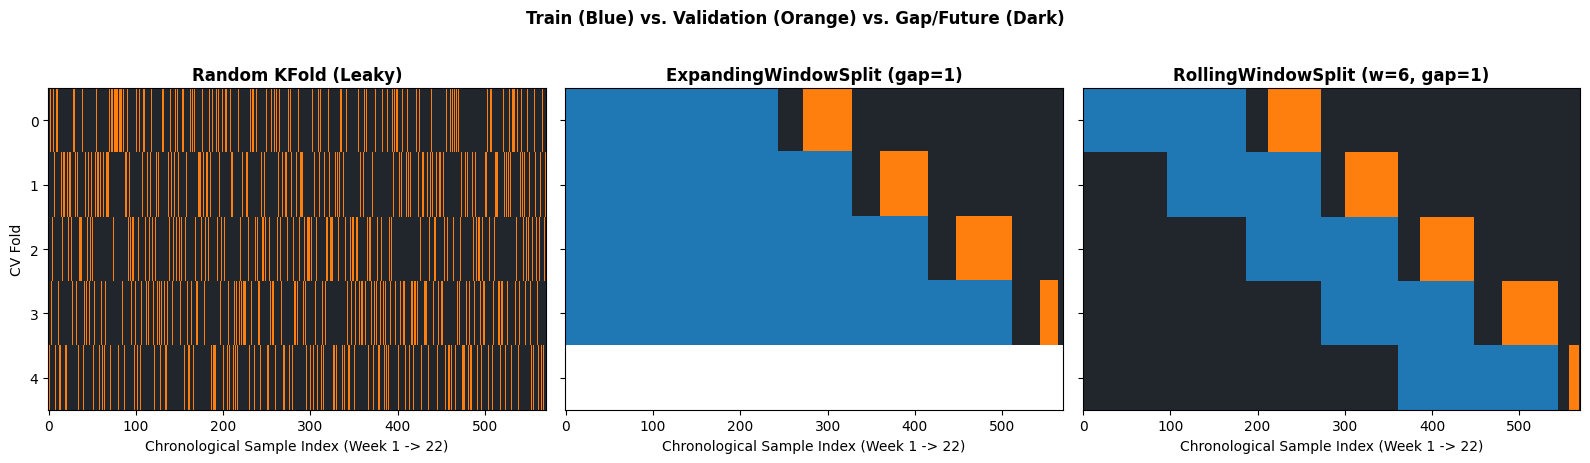

--- Controlled Data Leakage Experiment (Predicting mean_epa from Rolling Features) ---
                       strategy  rmse_mean  r2_mean
           Random KFold (Leaky)     0.1559   0.0286
   ExpandingWindowSplit (gap=1)     0.1381   0.1326
RollingWindowSplit (w=6, gap=1)     0.1434   0.1302


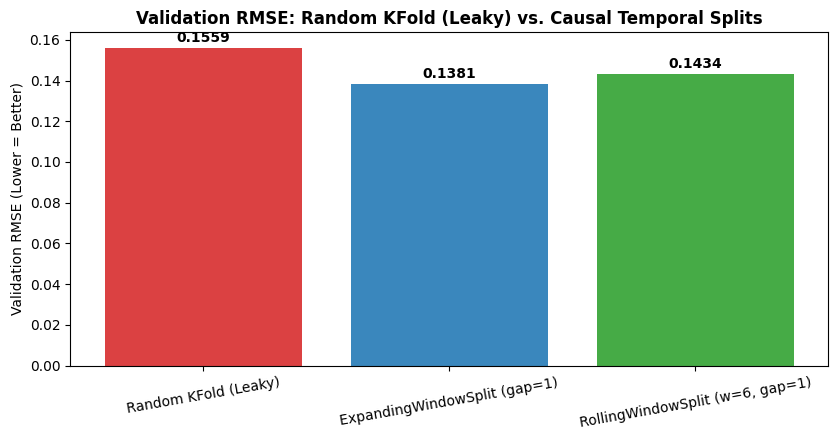

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, cross_validate

# Sort chronologically by week for clean visualization
df_exp = nfl_temp_df.sort_values(["week", "posteam"]).reset_index(drop=True)
weeks_sorted = df_exp["week"].values

rand_cv = KFold(n_splits=5, shuffle=True, random_state=42)
exp_cv = ExpandingWindowSplit(min_train_size=8, val_size=2, step_size=3, gap=1)
roll_cv = RollingWindowSplit(window_size=6, val_size=2, step_size=3, gap=1)

# 1. Visualize Train / Val / Excluded assignments across sorted observations
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
cmap_splits = ListedColormap(["#21262d", "#1f77b4", "#ff7f0e"])  # 0=Excluded/Gap, 1=Train, 2=Val

for ax, (title, cv_obj, use_groups) in zip(
    axes,
    [
        ("Random KFold (Leaky)", rand_cv, False),
        ("ExpandingWindowSplit (gap=1)", exp_cv, True),
        ("RollingWindowSplit (w=6, gap=1)", roll_cv, True),
    ],
):
    n_splits = cv_obj.get_n_splits(groups=weeks_sorted) if use_groups else cv_obj.get_n_splits(df_exp)
    mat = np.zeros((n_splits, len(df_exp)), dtype=int)
    iterator = cv_obj.split(df_exp, groups=weeks_sorted) if use_groups else cv_obj.split(df_exp)
    for f_idx, (tr, va) in enumerate(iterator):
        mat[f_idx, tr] = 1
        mat[f_idx, va] = 2
    ax.imshow(mat, aspect="auto", cmap=cmap_splits, interpolation="nearest")
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("Chronological Sample Index (Week 1 -> 22)")
axes[0].set_ylabel("CV Fold")
fig.suptitle("Train (Blue) vs. Validation (Orange) vs. Gap/Future (Dark)", fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

# 2. Controlled Data Leakage Experiment on rolling features
roll_cols = [c for c in df_exp.columns if "_roll_" in c]
df_model = df_exp.dropna(subset=roll_cols + ["mean_epa"]).reset_index(drop=True)
X_exp = df_model[roll_cols]
y_exp = df_model["mean_epa"]
w_exp = df_model["week"].values

rf = RandomForestRegressor(n_estimators=150, max_depth=8, random_state=42, n_jobs=-1)

results = []
for name, cv_obj, use_groups in [
    ("Random KFold (Leaky)", rand_cv, False),
    ("ExpandingWindowSplit (gap=1)", exp_cv, True),
    ("RollingWindowSplit (w=6, gap=1)", roll_cv, True),
]:
    cv_res = cross_validate(
        rf, X_exp, y_exp,
        cv=cv_obj,
        groups=w_exp if use_groups else None,
        scoring=["neg_root_mean_squared_error", "r2"],
    )
    results.append({
        "strategy": name,
        "rmse_mean": -cv_res["test_neg_root_mean_squared_error"].mean(),
        "r2_mean": cv_res["test_r2"].mean(),
    })

res_df = pd.DataFrame(results)
print("--- Controlled Data Leakage Experiment (Predicting mean_epa from Rolling Features) ---")
print(res_df.round(4).to_string(index=False))

fig2, ax2 = plt.subplots(figsize=(8.5, 4.5))
colors_bar = ["#d62728", "#1f77b4", "#2ca02c"]
ax2.bar(res_df["strategy"], res_df["rmse_mean"], color=colors_bar, alpha=0.88)
ax2.set_title("Validation RMSE: Random KFold (Leaky) vs. Causal Temporal Splits", fontweight="bold")
ax2.set_ylabel("Validation RMSE (Lower = Better)")
for i, v in enumerate(res_df["rmse_mean"]):
    ax2.text(i, v + 0.003, f"{v:.4f}", ha="center", fontweight="bold")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()


### Key Takeaways: Quantifying Look-Ahead Leakage

- **Visual proof of causality:** The split matrix confirms that `KFold(shuffle=True)` scatters validation points across all 22 weeks (mixing early-season noise with playoff weeks), whereas `ExpandingWindowSplit` and `RollingWindowSplit` maintain a strict past-to-future boundary with a 1-week embargo.
- **Regime distortion under random KFold:** Because `features_team_temporal_2023.parquet` already uses lagged rolling features, random `KFold` (`RMSE = 0.1559`, `R2 = 0.0286`) mixes volatile Weeks 1-4 into every fold and fails to capture true mid-to-late season predictive stability (`ExpandingWindowSplit`: `RMSE = 0.1381`, `R2 = 0.1326`; `RollingWindowSplit`: `RMSE = 0.1434`, `R2 = 0.1302`). From Day 37 onward, all Phase 3 predictive models will exclusively use `src/validation/temporal_cv.py`.

## 5. Production Hardening & Automated Unit Tests (`tests/test_temporal_cv.py`)

**Objective:** Verify our production enhancements to `src/validation/temporal_cv.py` (shared `_BaseTemporalWindowSplit`, `time_col` DataFrame support, strict `NaN` group rejection, `GridSearchCV` compatibility) by executing `tests/test_temporal_cv.py`.

**Engineering Rationale:** Because every Phase 3 model (Days 37-50) depends on `temporal_cv.py` to prevent look-ahead leakage, automated unit tests must verify causality invariants, zero train/val overlap, and `GridSearchCV` parameter cloning.

In [10]:
import subprocess

test_res = subprocess.run(
    [sys.executable, "-m", "unittest", "tests/test_temporal_cv.py", "-v"],
    cwd=REPO_ROOT,
    capture_output=True,
    text=True,
)
print(test_res.stderr.strip())
if test_res.returncode != 0:
    print(test_res.stdout.strip())
    raise RuntimeError(f"test_temporal_cv failed with code {test_res.returncode}")
print("[PASS] All temporal_cv unit tests passed.")


test_expanding_and_rolling_gap_enforcement (tests.test_temporal_cv.TestTemporalCV.test_expanding_and_rolling_gap_enforcement) ... ok
test_season_based_split_causality (tests.test_temporal_cv.TestTemporalCV.test_season_based_split_causality) ... ok
test_sklearn_cross_val_and_grid_search (tests.test_temporal_cv.TestTemporalCV.test_sklearn_cross_val_and_grid_search) ... ok
test_time_col_support_and_nan_rejection (tests.test_temporal_cv.TestTemporalCV.test_time_col_support_and_nan_rejection) ... ok

----------------------------------------------------------------------
Ran 4 tests in 0.016s

OK
[PASS] All temporal_cv unit tests passed.


### Key Takeaways: Production Readiness for Phase 3

- **Dry & hardened architecture:** Refactored all three splitters onto `_BaseTemporalWindowSplit` with `_resolve_time_groups`, supporting both `groups=...` and `time_col=...` while rejecting `NaN` timestamps loudly.
- **Automated regression guard:** `tests/test_temporal_cv.py` passes all 4 test suites (season causality, embargo gap enforcement, `time_col`/NaN checks, `cross_val_score`, and `GridSearchCV`).